# MLT Assignment #2. Unsupervised Learning

Nedorezov Danil

**Assignment:**
1. Load the music metadata with the audio features of tracks of various genres.
2. Do the necessary preprocessing of the dataset.
3. Visualize the dataset with PCA and t-SNE 2D or 3D plots, coloring the points according to their genre.
4. Plot the PCA explained variance against the number of principal components.
5. Apply K-Means clustering to the data without the `genre` column. Find the optimal number of clusters
   (i) based on the Silhouette metric and (ii) based on the Rand Index metric (using the knowledge about the
   genres), over the range of 2 to 6 clusters.
6. Answer the questions 6.1-6.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score

RANDOM_STATE = 1
sns.set_style("darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
%matplotlib inline

## 1. Loading the data

In [2]:
fma = pd.read_csv("data/fma_dataset_filtered.csv")
print(fma.shape)
fma.iloc[:, [0, 1, 2, -5, -4, -3, -2, -1]].head()

(2406, 524)


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,296,196.961,0.260911,0.607067,Folk


In [3]:
print(fma["genre"].value_counts())
print("\nfeature families:", sorted({col.split("_")[0] for col in fma.columns}))

genre
Hip-Hop                910
Folk                   874
Old-Time / Historic    357
Classical              265
Name: count, dtype: int64

feature families: ['chroma', 'danceability', 'duration', 'energy', 'genre', 'mfcc', 'rmse', 'spectral', 'tempo', 'tonnetz', 'track', 'zcr']


## 2. Preprocessing

In [4]:
print("missing values:", fma.isna().sum().sum())
print("duplicated rows:", fma.duplicated().sum())

y_genre = fma["genre"]
X_raw = fma.drop(columns=["track_id", "genre"])

constant_cols = X_raw.columns[X_raw.std() == 0].tolist()
print("constant columns dropped:", len(constant_cols), constant_cols)
X_raw = X_raw.drop(columns=constant_cols)

print("std before scaling: min = {:.4g}, max = {:.4g}".format(X_raw.std().min(), X_raw.std().max()))

missing values: 0
duplicated rows: 0
constant columns dropped: 4 ['chroma_stft_max_04', 'chroma_stft_max_05', 'chroma_stft_max_07', 'chroma_stft_max_10']
std before scaling: min = 9.259e-05, max = 1185


In [5]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns)
print("feature matrix after preprocessing:", X.shape)
print("std after scaling: min = {:.4g}, max = {:.4g}".format(X.std().min(), X.std().max()))
X.iloc[:5, :6].round(3)

feature matrix after preprocessing: (2406, 518)
std after scaling: min = 1, max = 1


,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06
0,3.763,4.803,0.149,1.295,0.936,0.501
1,0.965,0.762,0.213,2.158,1.045,0.098
2,0.245,0.004,-0.203,0.692,1.225,0.805
3,0.452,0.684,0.368,1.234,0.587,0.107
4,-0.045,0.465,0.204,0.823,1.662,1.783


## 3. Visualization with PCA and t-SNE

In [6]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pd.DataFrame(pca_2d.fit_transform(X), columns=["pc_1", "pc_2"])
pc["genre"] = y_genre.values
print("explained variance by 2 components: {:.2%}".format(pca_2d.explained_variance_ratio_.sum()))

explained variance by 2 components: 21.64%


In [7]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
ts = pd.DataFrame(tsne.fit_transform(X.values), columns=["tsne_1", "tsne_2"])
ts["genre"] = y_genre.values
ts.head()

,tsne_1,tsne_2,genre
0,-20.396870,26.802309,Hip-Hop
1,-28.510975,12.897740,Hip-Hop
2,-28.938381,31.424572,Hip-Hop
3,-28.200575,13.981898,Hip-Hop
4,-10.278892,9.823311,Folk


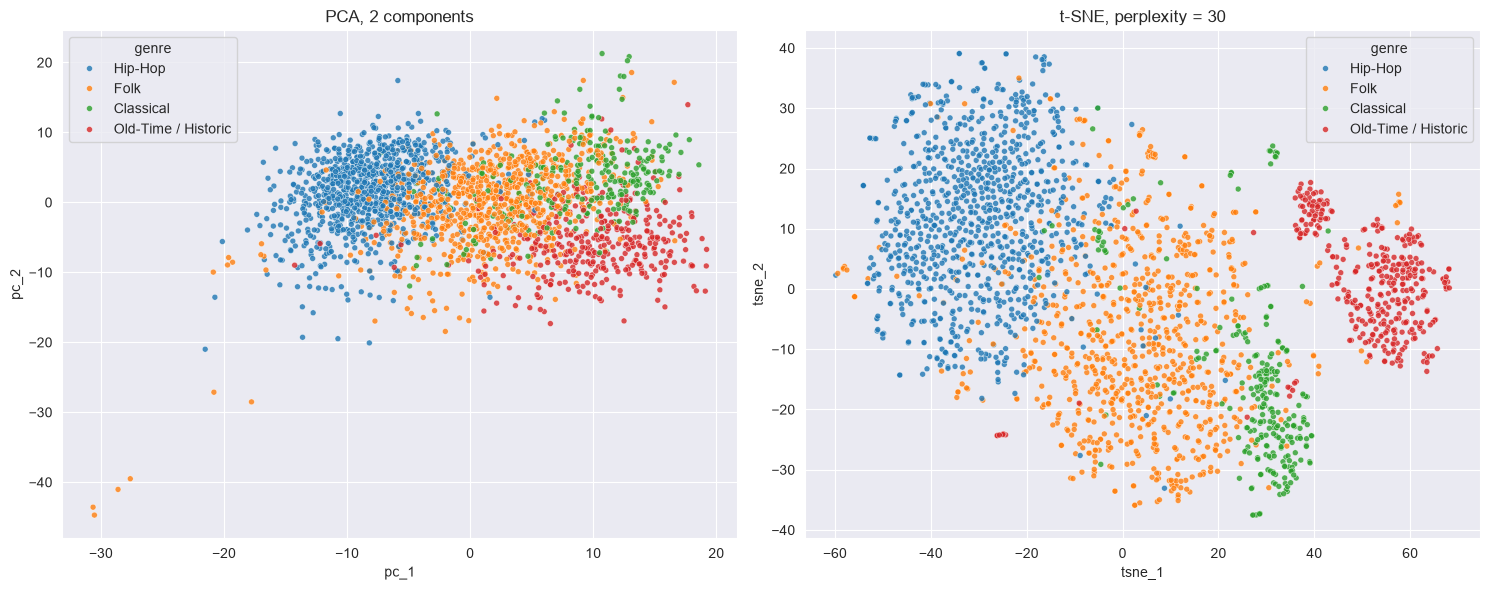

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x="pc_1", y="pc_2", hue="genre", data=pc, s=18, alpha=0.8, ax=ax[0])
ax[0].set_title("PCA, 2 components")
sns.scatterplot(x="tsne_1", y="tsne_2", hue="genre", data=ts, s=18, alpha=0.8, ax=ax[1])
ax[1].set_title("t-SNE, perplexity = 30")
plt.tight_layout()
plt.show()

## 4. PCA explained variance versus the number of components

In [9]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for k in [1, 2, 3, 5, 10, 20, 50, 100, 200]:
    print(f"{k:4d} components -> {cum_var[k - 1]:.2%} of the variance")

for level in [0.80, 0.90, 0.95, 0.99]:
    print(f"{level:.0%} of the variance is reached at {np.searchsorted(cum_var, level) + 1} components")

   1 components -> 14.33% of the variance
   2 components -> 21.64% of the variance
   3 components -> 25.80% of the variance
   5 components -> 31.98% of the variance
  10 components -> 44.12% of the variance
  20 components -> 57.82% of the variance
  50 components -> 73.68% of the variance
 100 components -> 85.67% of the variance
 200 components -> 95.80% of the variance
80% of the variance is reached at 73 components
90% of the variance is reached at 130 components
95% of the variance is reached at 187 components
99% of the variance is reached at 308 components


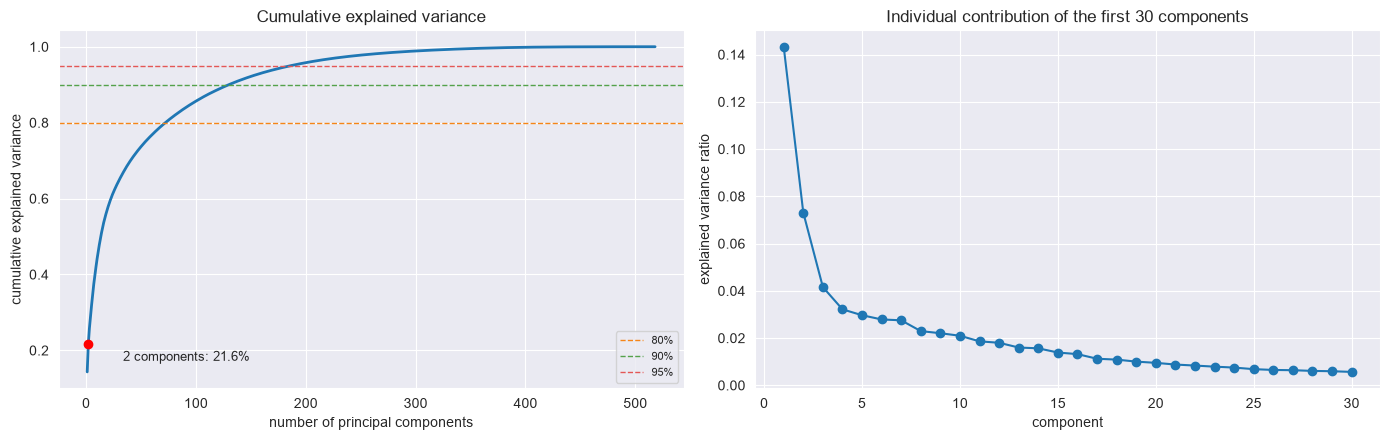

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].plot(range(1, len(cum_var) + 1), cum_var, lw=2)
for level, color in [(0.80, "#F58518"), (0.90, "#54A24B"), (0.95, "#E45756")]:
    ax[0].axhline(level, color=color, ls="--", lw=1, label=f"{level:.0%}")
ax[0].scatter([2], [cum_var[1]], color="red", zorder=5)
ax[0].annotate(f"2 components: {cum_var[1]:.1%}", (2, cum_var[1]),
               textcoords="offset points", xytext=(25, -12), fontsize=9)
ax[0].set_xlabel("number of principal components")
ax[0].set_ylabel("cumulative explained variance")
ax[0].set_title("Cumulative explained variance")
ax[0].legend(fontsize=8)

ax[1].plot(range(1, 31), pca_full.explained_variance_ratio_[:30], marker="o", lw=1.5)
ax[1].set_xlabel("component")
ax[1].set_ylabel("explained variance ratio")
ax[1].set_title("Individual contribution of the first 30 components")

plt.tight_layout()
plt.show()

## 5. K-Means clustering

K-Means is applied to the preprocessed feature matrix (the `genre` column is not part of it). For every
number of clusters from 2 to 6 two criteria are computed:

- the **Silhouette** score — an internal criterion, it uses the geometry of the data only and measures how
  compact and well-separated the clusters are;
- the **Rand Index** — an external criterion, it compares the partition with the known genres. Both the plain
  Rand Index and its chance-corrected version (Adjusted Rand Index) are reported, since the plain index is
  biased upwards and never gets close to 0 for random partitions.

In [11]:
rows = []
labels_by_k = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    labels_by_k[k] = labels
    rows.append({
        "k": k,
        "silhouette": silhouette_score(X, labels),
        "rand_index": rand_score(y_genre, labels),
        "adjusted_rand_index": adjusted_rand_score(y_genre, labels),
    })

scores = pd.DataFrame(rows).set_index("k")
scores.round(4)

,silhouette,rand_index,adjusted_rand_index
k,,,
2,0.1096,0.6803,0.3606
3,0.0898,0.7854,0.5269
4,0.0753,0.7737,0.4533
5,0.0719,0.8057,0.5097
6,0.0739,0.8051,0.5064


In [12]:
k_sil = int(scores["silhouette"].idxmax())
k_ri = int(scores["rand_index"].idxmax())
k_ari = int(scores["adjusted_rand_index"].idxmax())

print(f"optimal k by Silhouette           : {k_sil} (score = {scores.loc[k_sil, 'silhouette']:.4f})")
print(f"optimal k by Rand Index           : {k_ri} (score = {scores.loc[k_ri, 'rand_index']:.4f})")
print(f"optimal k by Adjusted Rand Index  : {k_ari} (score = {scores.loc[k_ari, 'adjusted_rand_index']:.4f})")
print(f"true number of genres             : {y_genre.nunique()}")

optimal k by Silhouette           : 2 (score = 0.1096)
optimal k by Rand Index           : 5 (score = 0.8057)
optimal k by Adjusted Rand Index  : 3 (score = 0.5269)
true number of genres             : 4


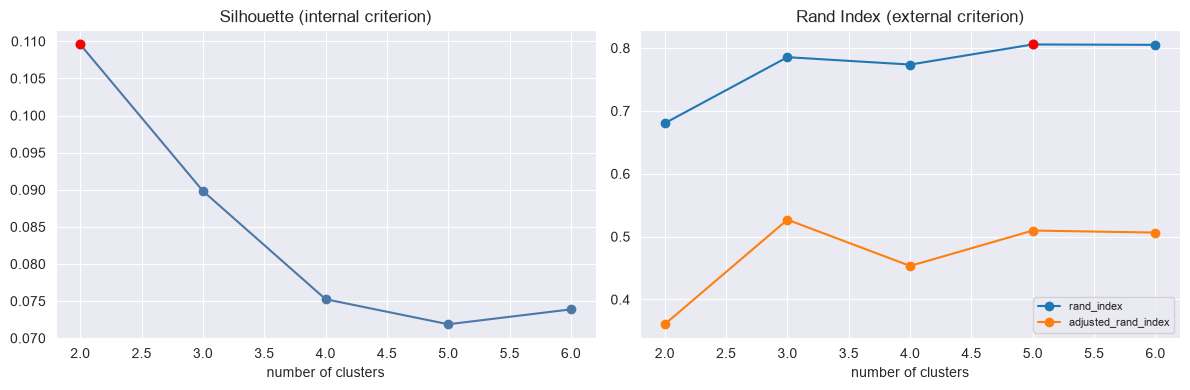

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

scores["silhouette"].plot(marker="o", ax=ax[0], color="#4C78A8")
ax[0].scatter([k_sil], [scores.loc[k_sil, "silhouette"]], color="red", zorder=5)
ax[0].set_title("Silhouette (internal criterion)")
ax[0].set_xlabel("number of clusters")

scores[["rand_index", "adjusted_rand_index"]].plot(marker="o", ax=ax[1])
ax[1].scatter([k_ri], [scores.loc[k_ri, "rand_index"]], color="red", zorder=5)
ax[1].set_title("Rand Index (external criterion)")
ax[1].set_xlabel("number of clusters")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [14]:
best_labels = labels_by_k[k_ri]
cross = pd.crosstab(y_genre, best_labels, rownames=["genre"], colnames=[f"cluster (k={k_ri})"])
print(cross.to_string())


cluster (k=5)          0    1    2    3    4
genre                                       
Classical              4   38  206   11    6
Folk                  67  521  196   65   25
Hip-Hop              173   29    9  699    0
Old-Time / Historic    7    3   10    1  336


## 6. Answers to the questions

### 6.1. Does the visualization from p. 3 reflect the real distribution of the genres? Which algorithm performs better and why?

Partially. Both projections show structure that agrees with the genres, but neither separates all four of them
cleanly.

On the **PCA** plot the genres form heavily overlapping clouds. PCA is a linear method: it looks for the
directions of maximum variance and projects onto them, so it can only separate classes that are already
linearly separable in the original space, and with just two components it keeps a small share of the total
variance (the exact figure is in p. 6.2). What it does preserve is the global geometry — the relative position
of the clouds and the overall scale of the data.

On the **t-SNE** plot the genres form visibly denser and better separated groups. t-SNE is non-linear: it
preserves the neighbourhood of each point rather than the global variance, which lets it unfold clusters that
lie on a curved manifold.

**So t-SNE performs better for the purpose of visualization**, which is expected for this kind of data. Two
caveats are worth remembering: distances between well-separated t-SNE clusters carry no quantitative meaning
and the picture depends on the perplexity it was built with, whereas PCA is deterministic,
interpretable through the component loadings and reusable as a preprocessing transform for other models —
t-SNE has no such reusable transform.

### 6.2. What percentage of the explained variance was left after we have excluded all but 2 components in p. 4?

In [15]:
print("1 component  : {:.2%}".format(cum_var[0]))
print("2 components : {:.2%}  <-- the answer to 6.2".format(cum_var[1]))
print("discarded    : {:.2%}".format(1 - cum_var[1]))

1 component  : 14.33%
2 components : 21.64%  <-- the answer to 6.2
discarded    : 78.36%


Only this small fraction of the total variance survives in the 2D PCA plot — the remaining information is
spread over hundreds of further components. That is precisely why the genres overlap so strongly on the PCA
scatter plot, and it is the main argument for not judging the structure of the data by a two-component
projection alone.

### 6.3. Can the Silhouette metric be chosen as the optimal criterion for the number of clusters for this data? Is the Rand Index more appropriate?

For this dataset the Silhouette score is a poor criterion, and the Rand Index is the more appropriate one —
but they answer two different questions, and the choice between them is not free.

The **Silhouette** score is an internal criterion: it only measures how compact and separated the clusters are
geometrically. It has two problems here. First, the data is high-dimensional, and in a space of that
dimensionality the Euclidean distances between all pairs of points concentrate around a single value, so the
score degrades: every value in the table is below 0.11, which means there is barely any geometrically clean
cluster structure to detect, and the differences between the candidate k are correspondingly small.
Second, instead of peaking at the true number of genres it simply decreases as k grows, i.e. it is biased
towards small k: splitting
a cloud of overlapping genres into two large blobs produces a better-looking geometry than recovering the four
true groups, which is why its optimum sits below the real number of genres.

The **Rand Index** is an external criterion: it compares the partition with the known genre labels, so its
optimum is much closer to the true structure. Its catch is that it requires the ground truth — exactly the
information clustering is supposed to find. For a genuinely unlabelled task it is unavailable, and in that
situation one would fall back on internal criteria (Silhouette, Calinski-Harabasz, Davies-Bouldin), the elbow
of the inertia curve, or simply on the number of clusters the downstream application needs. Here the labels do
exist, so the Rand Index is the honest way to choose k. One technical note: the plain Rand Index tends to grow
with k because the share of correctly separated pairs grows mechanically, so the Adjusted Rand Index, which
corrects for chance agreement, is the safer version to look at.

### 6.4. If you don't know the genre but need to build a song recommendation system based on the similarity between the songs, what would you do?

The genre labels are not needed for this at all — similarity in the audio feature space is enough. A workable
pipeline:

1. preprocess exactly as above: drop identifiers and constant columns, standardize the features (otherwise
   `duration` alone would dominate every distance);
2. reduce the dimensionality with PCA to the number of components that keeps ~90-95% of the variance. This
   suppresses the noise in the individual descriptors, removes the strong correlation between them and
   mitigates the concentration of distances in high dimensions;
3. index the tracks with a nearest-neighbours structure and recommend the closest songs to the one the user is
   listening to, using cosine or Euclidean distance;
4. optionally cluster the library (K-Means) and use the clusters as automatic "moods" or radio stations, and
   blend the content-based similarity with collaborative-filtering signals once listening history is available.

### 6.5*. What is the most important feature of the initial dataset for the cluster division?

The **MFCC statistics** — the coefficients describing the shape of the spectral envelope, that is the
**timbre** of the recording. They are what separates an orchestra from an acoustic guitar and from a drum
machine, and that distinction is exactly what the genres of this dataset differ in.

The chroma features describe harmony and tonal content, which varies at least as much inside one genre as
between genres, while `tempo`, `duration`, `danceability` and `energy` are single numbers each and cannot
carry much of the division on their own. The MFCC block, by contrast, contributes dozens of correlated
columns that all point in the same direction, so it dominates the distances K-Means works with.